# Lab 0 – Meet the data
*Session 1 · about 2 hours · work in pairs*

Before we let a computer identify animals, we look at what it will learn from. By the end of this lab you can
say how the dataset was made, what a *label* is, how the labels sit in the tree of life, and why the **dive** an
image comes from will matter later.

**How these notebooks work:** run cells from top to bottom with *Shift + Enter*. Cells marked ✍️ are questions for
you – write your answer in the cell below them (double-click to edit). You never have to write code from scratch;
at most you change a word or a number.

In [1]:
# Run this cell first. On Google Colab it fetches the course; on your own computer it only loads the data.
import os, subprocess, sys
from pathlib import Path
if "google.colab" in sys.modules:
    if not Path("/content/fathomnetchallange").exists():
        if Path("/content/fathomnetchallange.zip").exists():      # zip from your tutor (drag it into Files)
            subprocess.run(["unzip", "-q", "/content/fathomnetchallange.zip", "-d", "/content"], check=True)
        else:
            subprocess.run(["git", "clone", "-q", "https://github.com/TorbenGl/fathomnetchallange",
                            "/content/fathomnetchallange"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn", "fathomnet"], check=True)
    os.chdir("/content/fathomnetchallange/course")
sys.path.insert(0, str(Path.cwd()))

from setup_env import setup
ROOT = setup()          # first time: downloads the crops (~15 min). setup(per_category=100) is a quick subset.

import warnings; warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from classifier_lab import data, features, models, evaluate
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

Dataset ready: /home/user/fathomnetchallange/fathomnet2025_compact  (23698 crop files; exact duplicate boxes are dropped when loading)


## 1. One table, one row per animal
The official FathomNet 2025 training set has 8,981 deep-sea images. Experts drew a **box** around each animal
and named it. We cut each box out and shrank it to a 224 × 224 picture – a **crop**. Every crop is one row:

In [2]:
df = data.load_dataset()
print(len(df), "crops,", df["label"].nunique(), "labels,", df["image_id"].nunique(), "images,", df["dive"].nunique(), "dives")
df[["annotation_id", "image_id", "label", "phylum", "class", "order", "family", "genus", "species", "dive", "box_size"]].head(8)

23664 crops, 79 labels, 8979 images, 1465 dives


,annotation_id,image_id,label,phylum,class,order,family,genus,species,dive,box_size
0,1,1,Sebastolobus,Chordata,Teleostei,Perciformes,Sebastidae,Sebastolobus,,database.fathomnet.org/Ventana/images/3317,23.0
1,2,2,Apostichopus leukothele,Echinodermata,Holothuroidea,Synallactida,Stichopodidae,Apostichopus,Apostichopus leukothele,database.fathomnet.org/Ventana/images/4194,241.0
2,3,3,Scotoplanes,Echinodermata,Holothuroidea,Elasipodida,Elpidiidae,Scotoplanes,,database.fathomnet.org/Doc Ricketts/images/0617,577.0
3,4,4,Keratoisis,Cnidaria,Octocorallia,Scleralcyonacea,Keratoisididae,Keratoisis,,database.fathomnet.org/Doc Ricketts/images/1000,454.0
4,5,4,Keratoisis,Cnidaria,Octocorallia,Scleralcyonacea,Keratoisididae,Keratoisis,,database.fathomnet.org/Doc Ricketts/images/1000,534.0
5,6,5,Munnopsidae,Arthropoda,Malacostraca,Isopoda,Munnopsidae,,,database.fathomnet.org/Doc Ricketts/images/1376,86.0
6,7,6,Scotoplanes globosa,Echinodermata,Holothuroidea,Elasipodida,Elpidiidae,Scotoplanes,Scotoplanes globosa,database.fathomnet.org/Doc Ricketts/images/0673,175.0
7,8,7,Sebastolobus,Chordata,Teleostei,Perciformes,Sebastidae,Sebastolobus,,database.fathomnet.org/Doc Ricketts/images/0976,68.0


| column | meaning |
|---|---|
| `label` | the name the expert gave – one of **79 labels** |
| `phylum` … `species` | the label's lineage in the tree of life (from WoRMS, the World Register of Marine Species) |
| `image_id` | which video frame the crop was cut from (one frame can contain several animals) |
| `dive` | which ROV dive (or camera deployment) the frame comes from |
| `box_size` | the shorter side of the box in the original image, in pixels |

## 2. Look at the animals
Each row of the figure is one label, each picture one crop. Run the cell several times with a different `seed`.

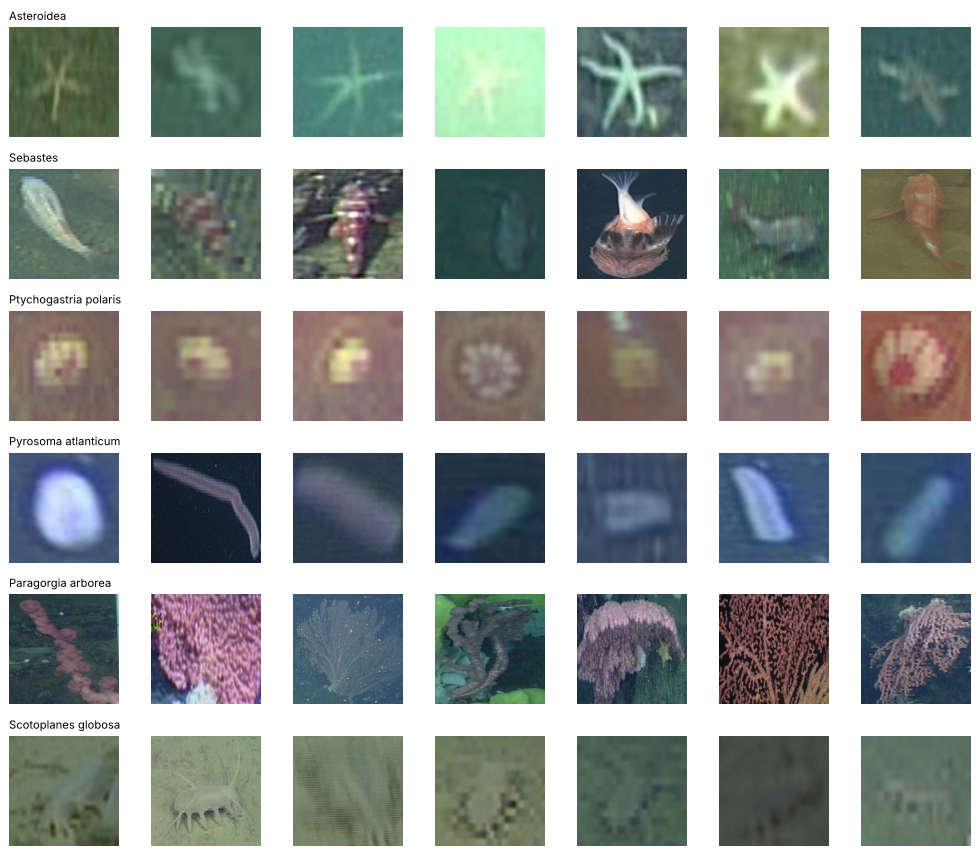

In [3]:
df["y"] = df["label"]
fig = data.show_examples(df, labels=["Asteroidea", "Sebastes", "Ptychogastria polaris", "Pyrosoma atlanticum",
                                     "Paragorgia arborea", "Scotoplanes globosa"], n=7, seed=0)

Pick labels you find interesting: the full list is printed below. Copy names into the list above and re-run.

In [4]:
print(", ".join(sorted(df["label"].unique())))

Abyssocucumis abyssorum, Acanthascinae, Acanthoptilum, Actinernus, Actiniaria, Actinopterygii, Amphipoda, Apostichopus leukothele, Asbestopluma, Asbestopluma monticola, Asteroidea, Benthocodon pedunculata, Brisingida, Caridea, Ceriantharia, Chionoecetes tanneri, Chorilia longipes, Corallimorphus pilatus, Crinoidea, Delectopecten, Elpidia, Farrea, Florometra serratissima, Funiculina, Gastropoda, Gersemia juliepackardae, Heterocarpus, Heterochone calyx, Heteropolypus ritteri, Hexactinellida, Hippasteria, Holothuroidea, Hormathiidae, Isidella tentaculum, Isididae, Isosicyonis, Keratoisis, Liponema brevicorne, Lithodidae, Mediaster aequalis, Merluccius productus, Metridium farcimen, Microstomus pacificus, Munidopsis, Munnopsidae, Mycale, Octopus rubescens, Ophiacanthidae, Ophiuroidea, Paelopatides confundens, Pandalus amplus, Pandalus platyceros, Pannychia moseleyi, Paragorgia, Paragorgia arborea, Paralomis multispina, Parastenella, Peniagone, Pennatula phosphorea, Porifera, Psathyrometra 

> ### ✍️ Q1
> Pick one label and describe its crops in two sentences, like a field-guide entry. Which *characters* (colour, shape, texture, background) would **you** use to recognise it? Which crops would even an expert find hard, and why?

*Your answer:*

## 3. How many examples per label, per phylum?

min    292.0
max    300.0
Name: crops, dtype: float64


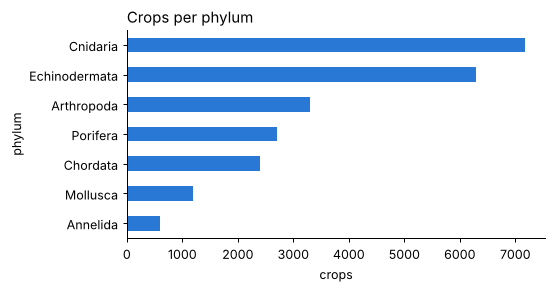

In [5]:
counts = df.groupby(["phylum", "label"]).size().rename("crops").reset_index()
print(counts["crops"].describe()[["min", "max"]])
ax = df["phylum"].value_counts().sort_values().plot.barh(color=evaluate.BLUE, figsize=(6, 3))
ax.set_xlabel("crops"); ax.set_title("Crops per phylum", loc="left");

> ### ✍️ Q2
> Every label has about 300 crops, but the phyla are very unequal. Why? (Hint: count the labels per phylum with `counts.groupby('phylum').size()`.) What could this mean for a classifier that predicts *phyla*?

*Your answer:*

## 4. Labels sit at different ranks
Not every label is a species. An expert names only what can be seen on the video: a blurry sea star stays
*Asteroidea* (a class). `label_rank` says at which rank each label sits.

In [6]:
tax = data.load_taxonomy()
display(tax["label_rank"].value_counts().to_frame("labels"))
tax.loc[["Sebastes diploproa", "Sebastes", "Asteroidea", "Porifera", "Tunicata"], ["label_rank", "phylum", "class", "order", "family", "genus"]]

,labels
label_rank,
species,33
genus,21
family,8
order,6
class,6
subfamily,1
gigaclass,1
infraorder,1
phylum,1


,label_rank,phylum,class,order,family,genus
label,,,,,,
Sebastes diploproa,species,Chordata,Teleostei,Perciformes,Sebastidae,Sebastes
Sebastes,genus,Chordata,Teleostei,Perciformes,Sebastidae,Sebastes
Asteroidea,class,Echinodermata,Asteroidea,,,
Porifera,phylum,Porifera,,,,
Tunicata,subphylum,Chordata,,,,


> ### ✍️ Q3
> Why is it a problem for a classifier that both *Sebastes* (a genus) and *Sebastes diploproa* (a species in that genus) are labels? What does a crop labelled *Sebastes* tell you about the species?

*Your answer:*

## 5. Dives: why the source of an image matters
A dive is a few hours of video from one place. Frames of one dive share the site, the light, the camera –
and often **the same individual animal**, filmed again a few seconds later.

1465 dives; the 10 largest contribute 21% of all crops


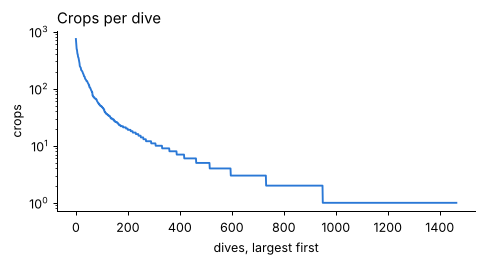

In [7]:
per_dive = df.groupby("dive").size().sort_values(ascending=False)
print(f"{len(per_dive)} dives; the 10 largest contribute {per_dive.head(10).sum() / len(df):.0%} of all crops")
ax = per_dive.reset_index(drop=True).plot(logy=True, color=evaluate.BLUE, figsize=(6, 2.6))
ax.set_xlabel("dives, largest first"); ax.set_ylabel("crops"); ax.set_title("Crops per dive", loc="left");

Crops of one label from **one** dive – how different are they really?

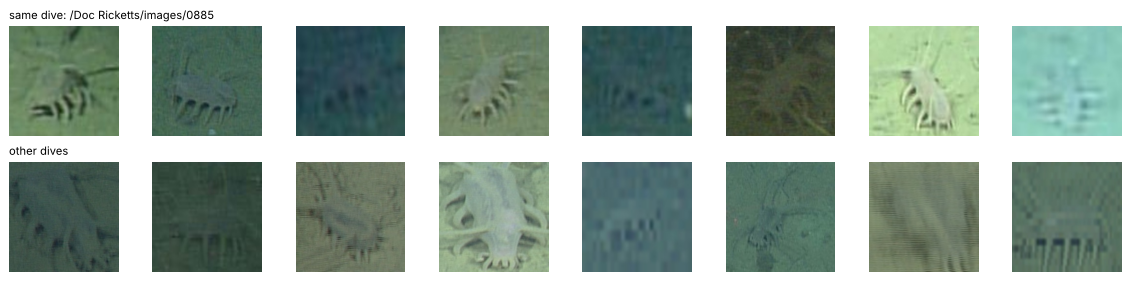

In [8]:
lab = "Scotoplanes globosa"
d = df[df["label"] == lab]
top_dive = d["dive"].value_counts().index[0]
one = d[d["dive"] == top_dive].copy(); one["y"] = "same dive: " + top_dive[-25:]
other = d[d["dive"] != top_dive].copy(); other["y"] = "other dives"
data.show_examples(pd.concat([one, other]), labels=[one["y"].iloc[0], "other dives"], n=8, seed=1);

> ### ✍️ Q4
> Imagine we train a classifier on half of the frames of a dive and test it on the other half. Why could the result look better than it really is? Keep your answer – we test it in Lab 3.

*Your answer:*

## 6. Tiny animals
Many boxes are small in the original image; the crop was blown up to 224 × 224 and is blurry.

0.193 of all crops come from a box smaller than 32 px


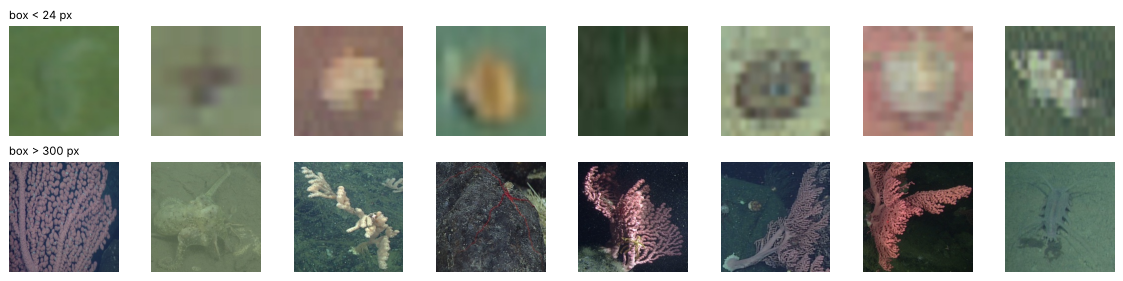

In [9]:
print((df["box_size"] < 32).mean().round(3), "of all crops come from a box smaller than 32 px")
small = df[df["box_size"] < 24].copy(); small["y"] = "box < 24 px"
big = df[df["box_size"] > 300].copy(); big["y"] = "box > 300 px"
data.show_examples(pd.concat([small, big]), labels=["box < 24 px", "box > 300 px"], n=8, seed=2);

## 7. Your group
From now on, each pair follows **one group** through all labs (e.g. sea stars = Asteroidea, soft corals = Octocorallia,
fish = Teleostei / Actinopterygii, sea cucumbers = Holothuroidea, sponges = Porifera, crabs and shrimps = Malacostraca).

1497 crops, 5 labels: Asteroidea, Brisingida, Hippasteria, Mediaster aequalis, Rathbunaster californicus


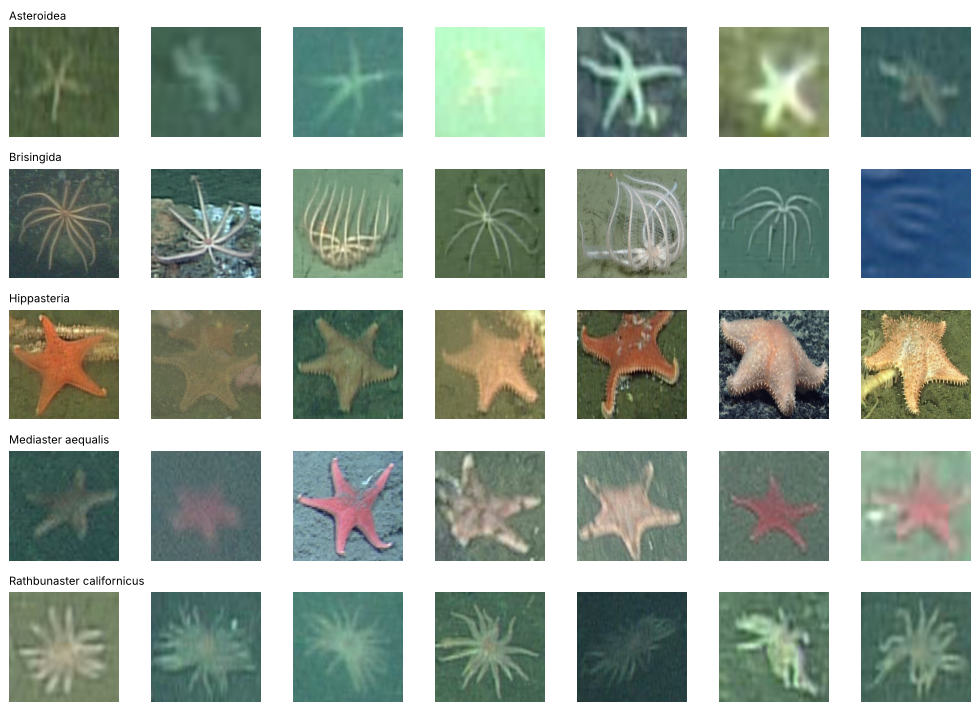

In [10]:
MY_RANK, MY_GROUP = "class", "Asteroidea"        # <- change to your group, e.g. ("phylum", "Porifera")
mine = df[df[MY_RANK] == MY_GROUP]
print(len(mine), "crops,", mine["label"].nunique(), "labels:", ", ".join(sorted(mine["label"].unique())))
mine = mine.assign(y=mine["label"])
data.show_examples(mine, labels=sorted(mine["label"].unique())[:6], n=7);

> ### ✍️ Q5
> Hand-in for Lab 0: name your group, list its labels, and save the figure above (right-click → save image). Which two labels of your group do you expect a computer to confuse most? Why?

*Your answer:*